# Phase-1 Reproduction (Local)

Reproduces, on the local Windows/RTX 3050 machine, the pipeline actually documented in
`results/phase1_lightning/Capstone_v1.ipynb` (the Lightning AI Studio notebook).

**Scope note (important):** the Lightning export also contained two much larger arrays —
`remoteclip_dota_features.npy` (28,767 crops, RemoteCLIP ViT-L/14, 768-dim) and
`finetuned_visdrone_features.npy` (217,153 crops, fine-tuned CLIP, 512-dim) — but the code that
produced them is **not present** in `Capstone_v1.ipynb`. Only the CLIP ViT-B/32 pipeline below
(893/312-crop sanity check + 300-image whole-image zero-shot drift experiment) is reproducible
from the available notebook. See the project's memory / chat log for the full breakdown; the
RemoteCLIP and fine-tuned-VisDrone stages are tracked as separate future work (Notebook 03), not
reproduced here.

Two sub-pipelines are reproduced, matching the historical notebook exactly:

- **Part A** — a small 5-image-per-dataset object-crop sanity check (historically used the
  `openai/CLIP` package; here it uses HF `transformers` CLIP with the same `ViT-B/32` weights to
  avoid installing an extra package — embeddings are equivalent, not identical bit-for-bit).
- **Part B** — the actual drift-bearing experiment: 300 whole DOTA images + 300 whole VisDrone
  images, classified zero-shot against a shared vocabulary, centroid drift computed per class.


In [1]:
import os
import json
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib
from tqdm import tqdm

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
# Local paths (see configs/experiment.yaml -> phase1_reproduction)
DOTA_IMG_DIR = "../data/raw/DOTA/images"
DOTA_LABEL_DIR = "../data/raw/DOTA/labelTxt"

VISDRONE_BASE = "../data/raw/VisDrone/VisDrone2019-DET-train"
VISDRONE_IMG_DIR = os.path.join(VISDRONE_BASE, "images")
VISDRONE_ANN_DIR = os.path.join(VISDRONE_BASE, "annotations")

EMBED_OUT = "../embeddings/phase1_local"
RESULTS_OUT = "../results/phase1_local"
os.makedirs(EMBED_OUT, exist_ok=True)
os.makedirs(RESULTS_OUT, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("DOTA images:", len(os.listdir(DOTA_IMG_DIR)))
print("DOTA labels:", len(os.listdir(DOTA_LABEL_DIR)))
print("VisDrone images:", len(os.listdir(VISDRONE_IMG_DIR)))
print("VisDrone annotations:", len(os.listdir(VISDRONE_ANN_DIR)))


DOTA images: 469
DOTA labels: 1411
VisDrone images: 6471
VisDrone annotations: 6471


## Part A — object-crop sanity check (5 images/dataset)

Matches `Capstone_v1.ipynb` cells 39-44. Uses HF `transformers` CLIP ViT-B/32 instead of the `openai/CLIP` package (same architecture/weights family, avoids an extra local install).

In [3]:
from transformers import CLIPModel, CLIPProcessor

crop_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
crop_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("Crop-test CLIP model loaded on:", device)


C:\anaconda\envs\hf\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Crop-test CLIP model loaded on: cuda


In [4]:
def parse_dota_label(label_path):
    boxes = []
    with open(label_path, "r") as f:
        lines = f.readlines()
    for line in lines:
        parts = line.strip().split()
        if len(parts) < 9:
            continue
        try:
            coords = list(map(float, parts[:8]))
        except ValueError:
            continue
        cls = parts[8]
        xs, ys = coords[0::2], coords[1::2]
        x_min, y_min = int(min(xs)), int(min(ys))
        x_max, y_max = int(max(xs)), int(max(ys))
        boxes.append((x_min, y_min, x_max, y_max, cls))
    return boxes


def get_dota_crops(max_images=5):
    crops = []
    img_files = sorted(os.listdir(DOTA_IMG_DIR))[:max_images]
    for img_name in img_files:
        img_path = os.path.join(DOTA_IMG_DIR, img_name)
        label_path = os.path.join(DOTA_LABEL_DIR, img_name.replace(".png", ".txt"))
        if not os.path.exists(label_path):
            continue
        image = Image.open(img_path).convert("RGB")
        for (x1, y1, x2, y2, cls) in parse_dota_label(label_path):
            crop = image.crop((x1, y1, x2, y2))
            if crop.size[0] == 0 or crop.size[1] == 0:
                continue
            crops.append((crop, cls))
    return crops


VISDRONE_CLASSES = {
    1: "pedestrian", 2: "person", 3: "bicycle", 4: "car", 5: "van",
    6: "truck", 7: "tricycle", 8: "awning-tricycle", 9: "bus", 10: "motor",
}


def get_visdrone_crops(max_images=5):
    crops = []
    img_files = sorted(os.listdir(VISDRONE_IMG_DIR))[:max_images]
    for img_name in img_files:
        img_path = os.path.join(VISDRONE_IMG_DIR, img_name)
        ann_path = os.path.join(VISDRONE_ANN_DIR, img_name.replace(".jpg", ".txt"))
        if not os.path.exists(ann_path):
            continue
        image = Image.open(img_path).convert("RGB")
        with open(ann_path, "r") as f:
            lines = f.readlines()
        for line in lines:
            parts = line.strip().split(",")
            x, y, w, h = map(int, parts[:4])
            cls_id = int(parts[5])
            if cls_id == 0:
                continue
            cls = VISDRONE_CLASSES.get(cls_id, "unknown")
            crop = image.crop((x, y, x + w, y + h))
            if crop.size[0] == 0 or crop.size[1] == 0:
                continue
            crops.append((crop, cls))
    return crops


def encode_crops(crops):
    image_features = []
    labels = []
    for crop, label in crops:
        inputs = crop_processor(images=crop, return_tensors="pt").to(device)
        with torch.no_grad():
            feat = crop_model.get_image_features(**inputs)
            feat = feat / feat.norm(dim=-1, keepdim=True)
        image_features.append(feat.cpu().numpy())
        labels.append(label)
    return np.vstack(image_features), np.array(labels)


In [5]:
dota_crops = get_dota_crops(max_images=5)
vis_crops = get_visdrone_crops(max_images=5)

dota_feats_local, dota_labels_local = encode_crops(dota_crops)
vis_feats_local, vis_labels_local = encode_crops(vis_crops)

print("Local DOTA crop features:", dota_feats_local.shape)
print("Local VisDrone crop features:", vis_feats_local.shape)

hist_dota = np.load("../embeddings/phase1_lightning/dota_feats.npy").shape
hist_vis = np.load("../embeddings/phase1_lightning/vis_feats.npy").shape
print("\nHistorical (Lightning) DOTA crop features:", hist_dota)
print("Historical (Lightning) VisDrone crop features:", hist_vis)
print("\nNote: exact crop counts may differ from history — file listing order and which 5 images")
print("get picked is filesystem-dependent (Linux vs Windows), so this is a sanity check on scale")
print("and embedding dimensionality, not an exact-count reproduction.")


Local DOTA crop features: (591, 512)
Local VisDrone crop features: (329, 512)

Historical (Lightning) DOTA crop features: (893, 512)
Historical (Lightning) VisDrone crop features: (312, 512)

Note: exact crop counts may differ from history — file listing order and which 5 images
get picked is filesystem-dependent (Linux vs Windows), so this is a sanity check on scale
and embedding dimensionality, not an exact-count reproduction.


In [6]:
np.save(os.path.join(EMBED_OUT, "dota_feats.npy"), dota_feats_local)
np.save(os.path.join(EMBED_OUT, "dota_labels.npy"), dota_labels_local)
np.save(os.path.join(EMBED_OUT, "vis_feats.npy"), vis_feats_local)
np.save(os.path.join(EMBED_OUT, "vis_labels.npy"), vis_labels_local)
print("Saved Part A embeddings to", EMBED_OUT)


Saved Part A embeddings to ../embeddings/phase1_local


## Part B — whole-image zero-shot drift experiment (300 images/domain)

Matches `Capstone_v1.ipynb` cells 45-92. This is the pipeline that actually produced the historical drift scores, PCA/t-SNE plots, and distance heatmap.

In [7]:
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

dota_class_names = ["plane", "ship", "vehicle", "building", "harbor"]

text_inputs = processor(text=dota_class_names, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    text_features = model.get_text_features(**text_inputs)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)


In [8]:
image_features_list = []
image_names = []

image_files = sorted(os.listdir(DOTA_IMG_DIR))

for img_name in tqdm(image_files[:300]):
    img_path = os.path.join(DOTA_IMG_DIR, img_name)
    try:
        image = Image.open(img_path).convert("RGB")
        inputs = processor(images=image, return_tensors="pt").to(device)
        with torch.no_grad():
            feat = model.get_image_features(**inputs)
            feat = feat / feat.norm(dim=-1, keepdim=True)
        image_features_list.append(feat.cpu().numpy())
        image_names.append(img_name)
    except Exception:
        continue

image_features_array = np.vstack(image_features_list)
print("DOTA whole-image features:", image_features_array.shape)


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 1/300 [00:00<03:11,  1.56it/s]

  1%|          | 2/300 [00:00<02:08,  2.31it/s]

  1%|          | 3/300 [00:01<01:38,  3.01it/s]

  2%|▏         | 5/300 [00:01<00:58,  5.01it/s]

...

 98%|█████████▊| 295/300 [00:34<00:00, 14.15it/s]

 99%|█████████▉| 297/300 [00:34<00:00, 12.93it/s]

100%|█████████▉| 299/300 [00:34<00:00, 12.13it/s]

100%|██████████| 300/300 [00:34<00:00,  8.67it/s]

DOTA whole-image features: (300, 512)


In [9]:
similarity = image_features_array @ text_features.cpu().numpy().T
predictions = similarity.argmax(axis=1)

for i in range(5):
    print(f"{image_names[i]} -> {dota_class_names[predictions[i]]}")


P0000.png -> plane
P0001.png -> harbor
P0002.png -> plane
P0005.png -> plane
P0008.png -> vehicle


In [10]:
# Shared vocabulary mapping (identical to Capstone_v1.ipynb cells 55-56)
dota_classes = [
    "plane", "ship", "storage-tank", "baseball-diamond", "tennis-court",
    "basketball-court", "ground-track-field", "harbor", "bridge",
    "large-vehicle", "small-vehicle", "helicopter", "roundabout",
    "soccer-ball-field", "swimming-pool",
]

class_mapping = {
    "plane": "aircraft", "helicopter": "aircraft",
    "small-vehicle": "vehicle", "large-vehicle": "vehicle",
    "ship": "watercraft",
    "harbor": "infrastructure", "bridge": "infrastructure", "roundabout": "infrastructure",
    "storage-tank": "industrial",
    "baseball-diamond": "sports-field", "tennis-court": "sports-field",
    "basketball-court": "sports-field", "soccer-ball-field": "sports-field",
    "ground-track-field": "sports-field",
    "swimming-pool": "recreational",
}

common_classes = sorted(set(class_mapping.values()))
print(common_classes)


['aircraft', 'industrial', 'infrastructure', 'recreational', 'sports-field', 'vehicle', 'watercraft']


In [11]:
mapped_predictions = [class_mapping.get(dota_class_names[p], dota_class_names[p]) for p in predictions]

text_inputs_common = processor(text=common_classes, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    text_features_common = model.get_text_features(**text_inputs_common)
    text_features_common = text_features_common / text_features_common.norm(dim=-1, keepdim=True)

similarity_common = image_features_array @ text_features_common.cpu().numpy().T
new_predictions = similarity_common.argmax(axis=1)
final_predictions = [common_classes[i] for i in new_predictions]

for i in range(5):
    print(f"{image_names[i]}: before={mapped_predictions[i]!r}  after_recompute={final_predictions[i]!r}")


P0000.png: before='aircraft'  after_recompute='infrastructure'
P0001.png: before='infrastructure'  after_recompute='watercraft'
P0002.png: before='aircraft'  after_recompute='aircraft'
P0005.png: before='aircraft'  after_recompute='aircraft'
P0008.png: before='vehicle'  after_recompute='sports-field'


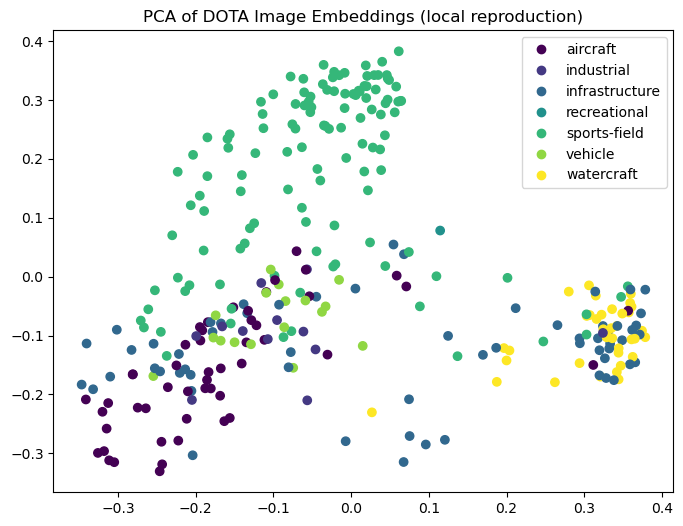

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
reduced_features = pca.fit_transform(image_features_array)

unique_labels = sorted(set(final_predictions))
label_to_int = {label: i for i, label in enumerate(unique_labels)}
numeric_labels = [label_to_int[l] for l in final_predictions]

plt.figure(figsize=(8, 6))
scatter = plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=numeric_labels)
plt.title("PCA of DOTA Image Embeddings (local reproduction)")
handles = [plt.Line2D([], [], marker='o', linestyle='', color=scatter.cmap(scatter.norm(idx)), label=label)
           for label, idx in label_to_int.items()]
plt.legend(handles=handles)
plt.savefig(os.path.join(RESULTS_OUT, "pca_dota.png"), dpi=150, bbox_inches="tight")
plt.show()


In [13]:
visdrone_features_list = []
visdrone_names = []

image_files_v = sorted(os.listdir(VISDRONE_IMG_DIR))

for img_name in tqdm(image_files_v[:300]):
    img_path = os.path.join(VISDRONE_IMG_DIR, img_name)
    try:
        image = Image.open(img_path).convert("RGB")
        inputs = processor(images=image, return_tensors="pt").to(device)
        with torch.no_grad():
            feat = model.get_image_features(**inputs)
            feat = feat / feat.norm(dim=-1, keepdim=True)
        visdrone_features_list.append(feat.cpu().numpy())
        visdrone_names.append(img_name)
    except Exception:
        continue

visdrone_features_array = np.vstack(visdrone_features_list)
print("VisDrone whole-image features:", visdrone_features_array.shape)


  0%|          | 0/300 [00:00<?, ?it/s]

  1%|          | 3/300 [00:00<00:12, 23.23it/s]

  2%|▏         | 6/300 [00:00<00:14, 20.10it/s]

  3%|▎         | 9/300 [00:00<00:15, 19.28it/s]

  4%|▎         | 11/300 [00:00<00:15, 18.97it/s]

...

 98%|█████████▊| 293/300 [00:14<00:00, 12.86it/s]

 99%|█████████▊| 296/300 [00:14<00:00, 15.53it/s]

100%|█████████▉| 299/300 [00:14<00:00, 17.68it/s]

100%|██████████| 300/300 [00:15<00:00, 19.99it/s]

VisDrone whole-image features: (300, 512)


In [14]:
similarity_visdrone = visdrone_features_array @ text_features_common.cpu().numpy().T
visdrone_preds_idx = similarity_visdrone.argmax(axis=1)
visdrone_predictions = [common_classes[i] for i in visdrone_preds_idx]

for i in range(5):
    print(f"{visdrone_names[i]} -> {visdrone_predictions[i]}")


0000002_00005_d_0000014.jpg -> vehicle
0000002_00448_d_0000015.jpg -> infrastructure
0000003_00231_d_0000016.jpg -> sports-field
0000007_04999_d_0000036.jpg -> vehicle
0000007_05499_d_0000037.jpg -> vehicle


**Methodological caveat (flagging per PROJECT_CONTEXT.md Section 14, not fixing silently):**
the "class" each image is grouped under below is the *model's own zero-shot prediction*
(`final_predictions` / `visdrone_predictions`), not ground-truth DOTA/VisDrone annotations.
That means the drift score computed next conflates two effects that are not separated:
(1) genuine cross-domain semantic drift within a true class, and (2) zero-shot
misclassification noise pulling images into the wrong class bucket in the first place.
This matches exactly how the historical Lightning notebook computed it — reproduced as-is here
for comparability — but it should be treated as a first-pass estimate, not final evidence, until
a ground-truth-labeled version of this analysis is run (using the actual DOTA/VisDrone box
annotations + the class mapping in PROJECT_CONTEXT.md Section 5, rather than model predictions).

In [15]:
combined_features = np.vstack([image_features_array, visdrone_features_array])
combined_labels = final_predictions + visdrone_predictions
domain_labels = (["satellite"] * len(final_predictions)) + (["uav"] * len(visdrone_predictions))

class_embeddings = {}
for i in range(len(combined_features)):
    cls = combined_labels[i]
    domain = domain_labels[i]
    class_embeddings.setdefault(cls, {"satellite": [], "uav": []})
    class_embeddings[cls][domain].append(combined_features[i])

class_centroids = {}
for cls, d in class_embeddings.items():
    sat = np.array(d["satellite"])
    uav = np.array(d["uav"])
    if len(sat) == 0 or len(uav) == 0:
        continue
    class_centroids[cls] = (sat.mean(axis=0), uav.mean(axis=0))

from numpy.linalg import norm

drift_scores = {cls: float(norm(sat_c - uav_c)) for cls, (sat_c, uav_c) in class_centroids.items()}

for cls, score in sorted(drift_scores.items(), key=lambda kv: kv[1]):
    print(f"{cls}: Drift Score = {score:.4f}")


industrial: Drift Score = 0.4589
aircraft: Drift Score = 0.5363
vehicle: Drift Score = 0.5641
sports-field: Drift Score = 0.6165
infrastructure: Drift Score = 0.6334
recreational: Drift Score = 0.8188


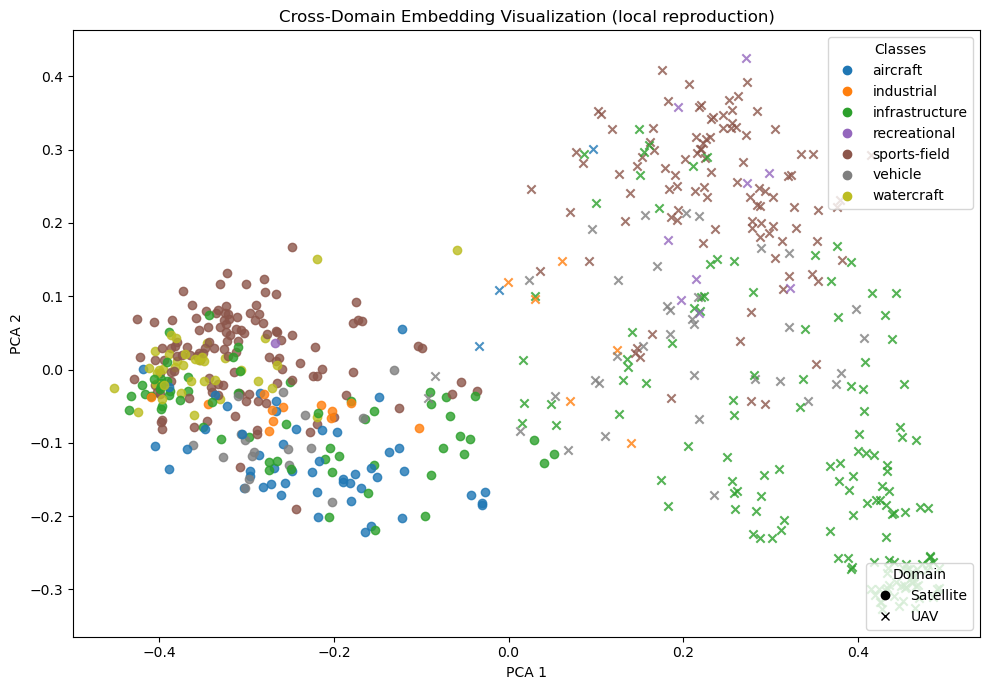

In [16]:
cmap = matplotlib.colormaps.get_cmap('tab10')
unique_classes = sorted(set(combined_labels))
class_to_color = {cls: cmap(i / len(unique_classes)) for i, cls in enumerate(unique_classes)}

pca_combined = PCA(n_components=2)
combined_reduced = pca_combined.fit_transform(combined_features)

plt.figure(figsize=(10, 7))
for i in range(len(combined_reduced)):
    cls = combined_labels[i]
    domain = domain_labels[i]
    color = class_to_color[cls]
    marker = 'o' if domain == "satellite" else 'x'
    plt.scatter(combined_reduced[i, 0], combined_reduced[i, 1], color=color, marker=marker, alpha=0.8)

plt.title("Cross-Domain Embedding Visualization (local reproduction)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
class_handles = [plt.Line2D([], [], marker='o', linestyle='', color=class_to_color[c], label=c) for c in unique_classes]
domain_handles = [
    plt.Line2D([], [], marker='o', linestyle='', color='black', label='Satellite'),
    plt.Line2D([], [], marker='x', linestyle='', color='black', label='UAV'),
]
legend1 = plt.legend(handles=class_handles, title="Classes", loc='upper right')
plt.gca().add_artist(legend1)
plt.legend(handles=domain_handles, title="Domain", loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_OUT, "pca_combined.png"), dpi=150, bbox_inches="tight")
plt.show()


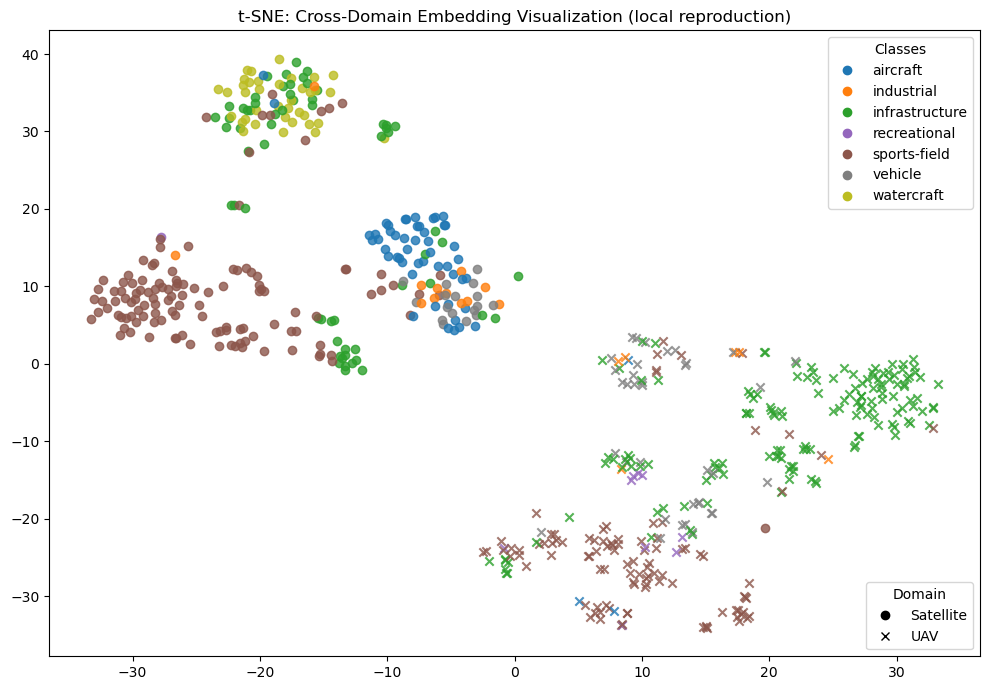

In [17]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=30, learning_rate=200, n_iter=1000, random_state=42)
tsne_features = tsne.fit_transform(combined_features)

plt.figure(figsize=(10, 7))
for i in range(len(tsne_features)):
    cls = combined_labels[i]
    domain = domain_labels[i]
    color = class_to_color[cls]
    marker = 'o' if domain == "satellite" else 'x'
    plt.scatter(tsne_features[i, 0], tsne_features[i, 1], color=color, marker=marker, alpha=0.8)

plt.title("t-SNE: Cross-Domain Embedding Visualization (local reproduction)")
class_handles = [plt.Line2D([], [], marker='o', linestyle='', color=class_to_color[c], label=c) for c in unique_classes]
domain_handles = [
    plt.Line2D([], [], marker='o', linestyle='', color='black', label='Satellite'),
    plt.Line2D([], [], marker='x', linestyle='', color='black', label='UAV'),
]
legend1 = plt.legend(handles=class_handles, title="Classes", loc='upper right')
plt.gca().add_artist(legend1)
plt.legend(handles=domain_handles, title="Domain", loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_OUT, "tsne_drift_local.png"), dpi=150, bbox_inches="tight")
plt.show()


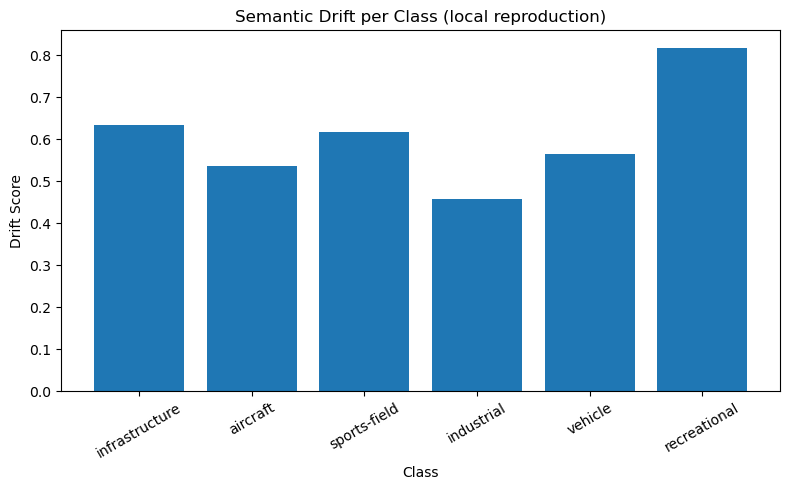

In [18]:
classes_sorted = list(drift_scores.keys())
scores_sorted = list(drift_scores.values())

plt.figure(figsize=(8, 5))
plt.bar(classes_sorted, scores_sorted)
plt.title("Semantic Drift per Class (local reproduction)")
plt.ylabel("Drift Score")
plt.xlabel("Class")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_OUT, "drift_scores_local.png"), dpi=150, bbox_inches="tight")
plt.show()


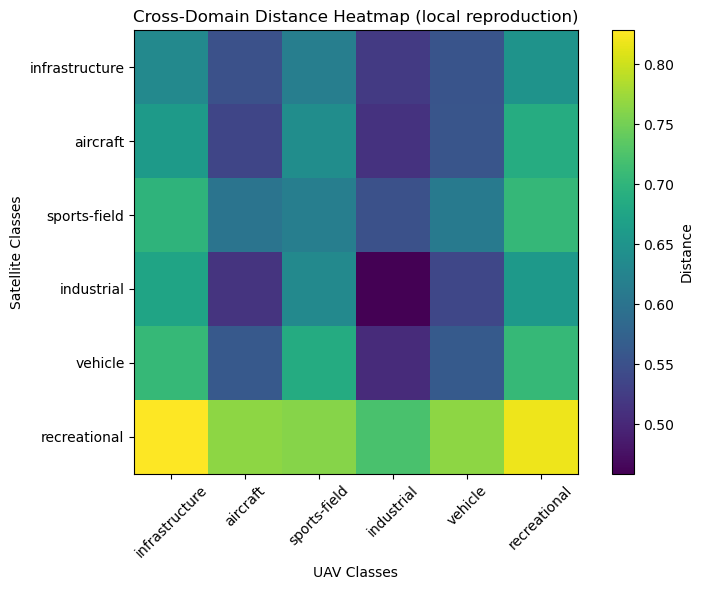

In [19]:
classes_h = list(class_centroids.keys())
n = len(classes_h)
distance_matrix = np.zeros((n, n))

for i, cls_sat in enumerate(classes_h):
    for j, cls_uav in enumerate(classes_h):
        sat_vec = class_centroids[cls_sat][0]
        uav_vec = class_centroids[cls_uav][1]
        distance_matrix[i, j] = norm(sat_vec - uav_vec)

plt.figure(figsize=(8, 6))
im = plt.imshow(distance_matrix)
plt.colorbar(im, label="Distance")
plt.xticks(range(n), classes_h, rotation=45)
plt.yticks(range(n), classes_h)
plt.xlabel("UAV Classes")
plt.ylabel("Satellite Classes")
plt.title("Cross-Domain Distance Heatmap (local reproduction)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_OUT, "distance_heatmap_local.png"), dpi=150, bbox_inches="tight")
plt.show()


In [20]:
np.save(os.path.join(EMBED_OUT, "dota_whole_image_feats.npy"), image_features_array)
np.save(os.path.join(EMBED_OUT, "dota_whole_image_predicted_labels.npy"), np.array(final_predictions))
np.save(os.path.join(EMBED_OUT, "visdrone_whole_image_feats.npy"), visdrone_features_array)
np.save(os.path.join(EMBED_OUT, "visdrone_whole_image_predicted_labels.npy"), np.array(visdrone_predictions))

with open(os.path.join(RESULTS_OUT, "drift_scores_local.json"), "w") as f:
    json.dump(drift_scores, f, indent=2)

print("Saved Part B embeddings + drift scores to", EMBED_OUT, "and", RESULTS_OUT)


Saved Part B embeddings + drift scores to ../embeddings/phase1_local and ../results/phase1_local


## Historical vs. local comparison

In [21]:
historical_drift_scores = {
    "sports-field": 0.5320,
    "infrastructure": 0.5714,
    "aircraft": 0.6093,
    "vehicle": 0.5907,
    "industrial": 0.7169,
}

print(f"{'class':<15}{'historical':>12}{'local':>12}{'delta':>12}")
for cls in sorted(set(historical_drift_scores) | set(drift_scores)):
    h = historical_drift_scores.get(cls)
    l = drift_scores.get(cls)
    if h is None or l is None:
        print(f"{cls:<15}{'n/a' if h is None else h:>12}{'n/a' if l is None else round(l,4):>12}{'':>12}")
    else:
        print(f"{cls:<15}{h:>12.4f}{l:>12.4f}{l-h:>12.4f}")


class            historical       local       delta
aircraft             0.6093      0.5363     -0.0730
industrial           0.7169      0.4589     -0.2580
infrastructure       0.5714      0.6334      0.0620
recreational            n/a      0.8188            
sports-field         0.5320      0.6165      0.0845
vehicle              0.5907      0.5641     -0.0266
